# Concentrated-prior parameter estimation: transformer versus statistical estimators

Four trained models, as reported in the paper: one seed (20260906), n_train=8, M=2^19; one-mode truncated Gaussian prior, S in {0.2,0.1}, q in {0.1,0.2}. No training or transformer inference is rerun.

Each comparison uses the same first 256 exported test examples, regenerated under the corresponding prior/noise setting and checked against cached parameters, targets, and query times. Context sizes use nested observations. All errors are MSE averaged over the three normalized parameter coordinates. **Transformer estimates are the mean of output tokens**, not all-token loss.

Bounded MLE uses SciPy bounded linear least squares on the original parameter box. At n=2 the design is underdetermined: the MLE may be nonunique and the curve represents the solver's selected solution. Projected SGD uses the same finite-budget protocol as notebook 03 (midpoint initialization, 3000 steps, observation minibatches of 8, initial rate 0.05). It need not reach the MLE.

The posterior mean uses the actual truncated Gaussian or equal two-component prior, Gaussian likelihood with physical noise SD q*S_X, Gaussian conditioning followed by adaptive scrambled-Sobol integration over the box. Convergence compares successive quadrature sizes, independent scrambles, effective sample size and mixture probabilities. These are numerical checks, not a proof of integration accuracy. Unconverged cases are explicitly reported and retained; inspect diagnostics before drawing conclusions.

Shading is a pointwise 95% percentile bootstrap CI for mean test error (5000 resamples of whole trajectories), conditional on this one trained seed. It does not measure training-seed uncertainty. The vertical dotted line marks training n=8. Cross-setting risks involve different test populations.

New statistical estimates are cached separately under statistical_comparison_cache/prior_screen, including posterior progress in blocks of 32 tasks. Reruns load completed computations. Figures are saved as PDF/PNG in figures/prior_screen.

Plots: one 1×2 figure per prior, S=0.2 left and S=0.1 right. Colors identify estimators; solid lines: q=0.1; dotted lines: q=0.2. Shared legend below.


In [1]:
from pathlib import Path
import sys, importlib
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "ode_paper").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "ode_paper").exists():
    raise RuntimeError("Open from Paper repo or its notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
import torch
torch.set_num_threads(2)
import matplotlib.pyplot as plt
import ode_paper.prior_comparison as comparison
importlib.reload(comparison)
COUNT = 256
NS = (2,4,8,16,32,64,128,256,512)
SETTINGS = dict(count=COUNT, ns=NS, sgd_steps=3000, sgd_batch=8, sgd_lr=.05)
QUADRATURE = dict(comparison.DEFAULT_QUADRATURE)
RESULTS = []


## one mode: S=0.2, q=0.1


In [2]:
one_mode_s02_q01 = comparison.compare_setting(ROOT, "one_mode", 0.2, 0.1,
    quadrature=QUADRATURE, **SETTINGS)
RESULTS = [r for r in RESULTS if (r["prior"],r["s"],r["q"]) != ("one_mode",0.2,0.1)]
RESULTS.append(one_mode_s02_q01)


one_mode S=0.2 q=0.1 n=2: Transformer=0.0252541, Posterior mean=0.0210403, Bounded MLE=0.0823257, Projected SGD=0.0428647; posterior unconverged=0/256
one_mode S=0.2 q=0.1 n=4: Transformer=0.0168514, Posterior mean=0.0146882, Bounded MLE=0.108021, Projected SGD=0.0317347; posterior unconverged=0/256
one_mode S=0.2 q=0.1 n=8: Transformer=0.0100535, Posterior mean=0.00981595, Bounded MLE=0.0335098, Projected SGD=0.0162181; posterior unconverged=0/256
one_mode S=0.2 q=0.1 n=16: Transformer=0.00500752, Posterior mean=0.00454051, Bounded MLE=0.00713122, Projected SGD=0.00583245; posterior unconverged=0/256
one_mode S=0.2 q=0.1 n=32: Transformer=0.00281847, Posterior mean=0.00183657, Bounded MLE=0.00210919, Projected SGD=0.00204357; posterior unconverged=0/256
one_mode S=0.2 q=0.1 n=64: Transformer=0.00230426, Posterior mean=0.00111233, Bounded MLE=0.00119304, Projected SGD=0.00118092; posterior unconverged=0/256
one_mode S=0.2 q=0.1 n=128: Transformer=0.00191136, Posterior mean=0.000561817,

## one mode: S=0.2, q=0.2


In [3]:
one_mode_s02_q02 = comparison.compare_setting(ROOT, "one_mode", 0.2, 0.2,
    quadrature=QUADRATURE, **SETTINGS)
RESULTS = [r for r in RESULTS if (r["prior"],r["s"],r["q"]) != ("one_mode",0.2,0.2)]
RESULTS.append(one_mode_s02_q02)


one_mode S=0.2 q=0.2 n=2: Transformer=0.0288768, Posterior mean=0.0247142, Bounded MLE=0.132696, Projected SGD=0.0901669; posterior unconverged=0/256


one_mode S=0.2 q=0.2 n=4: Transformer=0.021633, Posterior mean=0.0198051, Bounded MLE=0.169843, Projected SGD=0.0858923; posterior unconverged=0/256
one_mode S=0.2 q=0.2 n=8: Transformer=0.0157782, Posterior mean=0.0159326, Bounded MLE=0.0800008, Projected SGD=0.0536889; posterior unconverged=0/256
one_mode S=0.2 q=0.2 n=16: Transformer=0.0114185, Posterior mean=0.0103195, Bounded MLE=0.0265511, Projected SGD=0.0227567; posterior unconverged=0/256
one_mode S=0.2 q=0.2 n=32: Transformer=0.008895, Posterior mean=0.00568208, Bounded MLE=0.00843674, Projected SGD=0.00818767; posterior unconverged=0/256
one_mode S=0.2 q=0.2 n=64: Transformer=0.00811445, Posterior mean=0.00378907, Bounded MLE=0.00475913, Projected SGD=0.00471777; posterior unconverged=0/256
one_mode S=0.2 q=0.2 n=128: Transformer=0.00744312, Posterior mean=0.00205734, Bounded MLE=0.00232215, Projected SGD=0.00237112; posterior unconverged=0/256
one_mode S=0.2 q=0.2 n=256: Transformer=0.00727649, Posterior mean=0.00114814, Bo

## one mode: S=0.1, q=0.1


In [4]:
one_mode_s01_q01 = comparison.compare_setting(ROOT, "one_mode", 0.1, 0.1,
    quadrature=QUADRATURE, **SETTINGS)
RESULTS = [r for r in RESULTS if (r["prior"],r["s"],r["q"]) != ("one_mode",0.1,0.1)]
RESULTS.append(one_mode_s01_q01)


one_mode S=0.1 q=0.1 n=2: Transformer=0.00735583, Posterior mean=0.00626343, Bounded MLE=0.0702228, Projected SGD=0.0319021; posterior unconverged=0/256


one_mode S=0.1 q=0.1 n=4: Transformer=0.00557421, Posterior mean=0.00502165, Bounded MLE=0.113412, Projected SGD=0.0282091; posterior unconverged=0/256
one_mode S=0.1 q=0.1 n=8: Transformer=0.00403974, Posterior mean=0.00403286, Bounded MLE=0.0334123, Projected SGD=0.0147457; posterior unconverged=0/256
one_mode S=0.1 q=0.1 n=16: Transformer=0.00282303, Posterior mean=0.0026063, Bounded MLE=0.00713122, Projected SGD=0.00572099; posterior unconverged=0/256
one_mode S=0.1 q=0.1 n=32: Transformer=0.00212962, Posterior mean=0.0014271, Bounded MLE=0.00210919, Projected SGD=0.00205146; posterior unconverged=0/256
one_mode S=0.1 q=0.1 n=64: Transformer=0.00194622, Posterior mean=0.000954323, Bounded MLE=0.00119304, Projected SGD=0.00118454; posterior unconverged=0/256
one_mode S=0.1 q=0.1 n=128: Transformer=0.0017752, Posterior mean=0.00051504, Bounded MLE=0.000581978, Projected SGD=0.000594274; posterior unconverged=0/256
one_mode S=0.1 q=0.1 n=256: Transformer=0.00172785, Posterior mean=0.0

## one mode: S=0.1, q=0.2


In [5]:
one_mode_s01_q02 = comparison.compare_setting(ROOT, "one_mode", 0.1, 0.2,
    quadrature=QUADRATURE, **SETTINGS)
RESULTS = [r for r in RESULTS if (r["prior"],r["s"],r["q"]) != ("one_mode",0.1,0.2)]
RESULTS.append(one_mode_s01_q02)


one_mode S=0.1 q=0.2 n=2: Transformer=0.00907666, Posterior mean=0.00733462, Bounded MLE=0.121397, Projected SGD=0.0799069; posterior unconverged=0/256
one_mode S=0.1 q=0.2 n=4: Transformer=0.00692642, Posterior mean=0.0063135, Bounded MLE=0.176097, Projected SGD=0.0852283; posterior unconverged=0/256
one_mode S=0.1 q=0.2 n=8: Transformer=0.00560696, Posterior mean=0.00561359, Bounded MLE=0.082395, Projected SGD=0.0538473; posterior unconverged=0/256
one_mode S=0.1 q=0.2 n=16: Transformer=0.00462461, Posterior mean=0.00447383, Bounded MLE=0.0269177, Projected SGD=0.0226677; posterior unconverged=0/256
one_mode S=0.1 q=0.2 n=32: Transformer=0.00402616, Posterior mean=0.00318977, Bounded MLE=0.00843674, Projected SGD=0.00821031; posterior unconverged=0/256
one_mode S=0.1 q=0.2 n=64: Transformer=0.00383294, Posterior mean=0.0024866, Bounded MLE=0.00477217, Projected SGD=0.00474306; posterior unconverged=0/256
one_mode S=0.1 q=0.2 n=128: Transformer=0.00367371, Posterior mean=0.00156343, B

## Single-mode prior


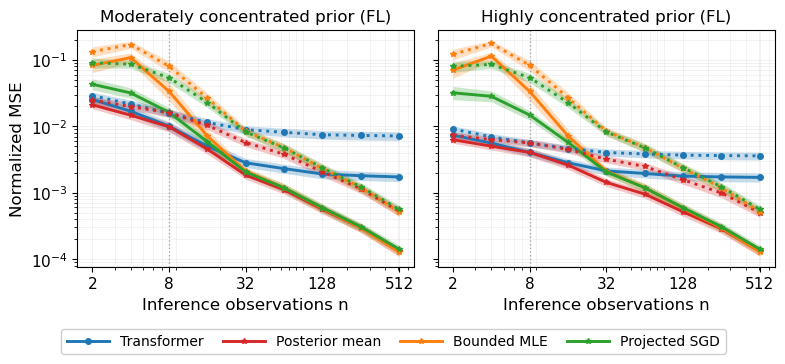

In [10]:
fig, axes = comparison.plot_prior_pair(ROOT, RESULTS, "one_mode")
plt.show()


## Numerical checks and paired comparisons
A positive MLE-minus-transformer (or MLE-minus-posterior) gap favors the latter. Paired intervals resample the same task indices for both methods. Claims about many contexts/settings require multiplicity caution; these are pointwise exploratory intervals. A posterior diagnostic failure is not hidden by dropping the task.


In [ ]:
import numpy as np
import pandas as pd
summary = comparison.summary_frame(RESULTS)
OUT = ROOT / "figures" / "prior_screen"
summary.to_csv(OUT / "parameter_comparison_summary.csv", index=False)
diagnostics, gaps = [], []
for result in RESULTS:
    for record in result["records"]:
        d = record["posterior_diagnostics"]
        diagnostics.append(dict(prior=result["prior"],s=result["s"],q=result["q"],n=record["n"],
            unconverged=int(np.sum(d[:,0]==0)), max_quad_change=d[:,1].max(),
            min_ess=d[:,2].min(), max_power=d[:,3].max(),
            median_sgd_projected_gradient=np.median(record["sgd_diagnostics"][:,2]),
            sgd_objective_increased=int(np.sum(record["sgd_diagnostics"][:,1] >
                                               record["sgd_diagnostics"][:,0]+1e-12))))
        for method in ("Transformer","Posterior mean"):
            delta=record["errors"]["Bounded MLE"]-record["errors"][method]
            rng=np.random.default_rng(7731+record["n"])
            means=np.array([delta[rng.integers(len(delta),size=len(delta))].mean() for _ in range(5000)])
            lo,hi=np.quantile(means,[.025,.975])
            gaps.append(dict(prior=result["prior"],s=result["s"],q=result["q"],n=record["n"],
                             method=method,mle_minus_method=delta.mean(),ci_low=lo,ci_high=hi))
diagnostics=pd.DataFrame(diagnostics)
gaps=pd.DataFrame(gaps)
diagnostics.to_csv(OUT/"numerical_diagnostics.csv",index=False)
gaps.to_csv(OUT/"paired_mle_gaps.csv",index=False)
display(diagnostics)
display(summary[summary.n.isin([8,128,512])])
display(gaps[gaps.n.isin([8,128,512])])
if diagnostics.unconverged.sum():
    print("WARNING: posterior quadrature did not pass all checks. Increase quadrature budget before relying on those cases.")
else:
    print("All posterior estimates passed the configured numerical checks.")
print("Figures and summaries:", OUT)
